In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
tf.random.set_seed(SEED)

df = pd.read_csv("ims_features_dataset.csv")
print(df.shape)

(232400, 30)


## Settings and features

In [2]:
TARGET = "RUL_hours"
LEAKAGE_COLUMNS = ["failure_timestamp", "RUL_minutes", "RUL_fraction", "health_index", "failure_risk_score"]
META_COLUMNS    = ["test_set", "bearing", "recording_index", "window_index", "timestamp"]
DROP_CORRELATED = ["rms", "peak_to_peak", "crest_factor", "spectral_energy", "variance", "spectral_entropy"]

FEATURES = [c for c in df.select_dtypes(include=np.number).columns
            if c not in [TARGET, *LEAKAGE_COLUMNS, *META_COLUMNS, *DROP_CORRELATED]]
print(len(FEATURES), FEATURES)

SEQ_LEN      = 30     # recordings per input sequence
CAP_HOURS    = 150.0  # RUL above this is treated as "healthy" (target = 100). Try 100 / 300 too.
HEALTHY_FRAC = 0.15   # first part of each run used to compute its scaling
CLIP         = 20.0

DEFECT_TYPE_MAP = {
    ("1st_test", "bearing_3"): "inner_race",
    ("1st_test", "bearing_4"): "roller_element",
    ("2nd_test", "bearing_1"): "outer_race",
    ("3rd_test", "bearing_3"): "outer_race",
}

13 ['mean', 'std', 'peak', 'skewness', 'kurtosis', 'shape_factor', 'impulse_factor', 'energy', 'mean_absolute', 'dominant_frequency', 'spectral_centroid', 'spectral_bandwidth', 'max_psd']


## One clean series per run (one row per recording) + capped health target

In [3]:
def build_run(test_set, bearing):
    r = df[(df["test_set"] == test_set) & (df["bearing"] == bearing)].copy()
    r["timestamp"] = pd.to_datetime(r["timestamp"])
    assert (r.groupby("recording_index")[TARGET].nunique() == 1).all()
    rec = (r.groupby("recording_index")
             .agg({**{f: "mean" for f in FEATURES}, "timestamp": "first", TARGET: "first"})
             .sort_values("timestamp").reset_index(drop=True))
    rec["life_hours"] = rec[TARGET].max()
    rec["health"] = np.minimum(rec[TARGET], CAP_HOURS) / CAP_HOURS * 100.0   # 100 = healthy, 0 = failure
    return rec

runs_df = {f"{d}|{ts}|{b}": build_run(ts, b) for (ts, b), d in DEFECT_TYPE_MAP.items()}
for n, r in runs_df.items():
    print(f"{n:38s} recordings={len(r):5d}  life={r['life_hours'].iloc[0]:7.1f} h  "
          f"share at cap={np.mean(r[TARGET] >= CAP_HOURS):.0%}")

inner_race|1st_test|bearing_3          recordings= 2156  life=  827.6 h  share at cap=69%
roller_element|1st_test|bearing_4      recordings= 2156  life=  827.6 h  share at cap=69%
outer_race|2nd_test|bearing_1          recordings=  984  life=  163.8 h  share at cap=9%
outer_race|3rd_test|bearing_3          recordings= 6324  life= 1073.3 h  share at cap=86%


## Per-run scaling and sequences (never cross a run boundary)

In [4]:
def make_sequences(X, y, L):
    ends = np.arange(L, len(X) + 1)
    return (np.stack([X[e - L:e] for e in ends]).astype("float32"), y[ends - 1].astype("float32"))

runs = {}
for name, rec in runs_df.items():
    n_h = int(len(rec) * HEALTHY_FRAC)
    sc = StandardScaler().fit(rec[FEATURES].iloc[:n_h])
    X = np.clip(sc.transform(rec[FEATURES]), -CLIP, CLIP)
    Xs, ys = make_sequences(X, rec["health"].values, SEQ_LEN)
    runs[name] = {"X": Xs, "y": ys, "life": rec["life_hours"].iloc[0]}
    print(name, Xs.shape)

inner_race|1st_test|bearing_3 (2127, 30, 13)
roller_element|1st_test|bearing_4 (2127, 30, 13)
outer_race|2nd_test|bearing_1 (955, 30, 13)
outer_race|3rd_test|bearing_3 (6295, 30, 13)


## Model and helpers

In [5]:
def build_1d_cnn(seq_len, n_features):
    m = keras.Sequential([
        layers.Input(shape=(seq_len, n_features)),
        layers.Conv1D(64, 5, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1),                       # linear output (targets are 0-1 after /100)
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss=keras.losses.Huber(), metrics=["mae"])
    return m

def block_split(n, block=200, frac=0.15, gap=SEQ_LEN):
    # contiguous validation blocks from inside a run, with a gap so train/val sequences do not overlap
    n_blocks = int(np.ceil(n / block))
    val_blocks = rng.choice(n_blocks, max(1, int(n_blocks * frac)), replace=False)
    is_val = np.zeros(n, bool); is_gap = np.zeros(n, bool)
    for b in val_blocks:
        s, e = b * block, min((b + 1) * block, n)
        is_val[s:e] = True
        is_gap[max(0, s - gap):s] = True
        is_gap[e:min(n, e + gap)] = True
    return ~is_val & ~is_gap, is_val

keras.backend.clear_session()
build_1d_cnn(SEQ_LEN, len(FEATURES)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,017 (148.50 KB)

 Trainable params: 37,633 (147.00 KB)

 Non-trainable params: 384 (1.50 KB)

## Leave-one-run-out training (4 folds)

In [6]:
results, preds, histories = [], {}, {}

for test_name in runs:
    train_names = [n for n in runs if n != test_name]
    Xtr, ytr, Xva, yva = [], [], [], []
    for n in train_names:
        tr, va = block_split(len(runs[n]["X"]))
        Xtr.append(runs[n]["X"][tr]); ytr.append(runs[n]["y"][tr])
        Xva.append(runs[n]["X"][va]); yva.append(runs[n]["y"][va])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr) / 100.0
    Xva, yva = np.concatenate(Xva), np.concatenate(yva) / 100.0
    X_te, y_te = runs[test_name]["X"], runs[test_name]["y"]
    print(f"\n=== TEST: {test_name} | train seqs={len(Xtr)} val seqs={len(Xva)} test seqs={len(X_te)} ===")

    keras.backend.clear_session()
    model = build_1d_cnn(SEQ_LEN, len(FEATURES))
    hist = model.fit(
        Xtr, ytr, validation_data=(Xva, yva), epochs=60, batch_size=64, shuffle=True, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)],
    )
    p = np.clip(model.predict(X_te, batch_size=256, verbose=0).ravel() * 100.0, 0, 100)
    err = p - y_te
    ss_res, ss_tot = np.sum(err ** 2), np.sum((y_te - y_te.mean()) ** 2)
    results.append({
        "test_run": test_name,
        "MAE_pts": np.mean(np.abs(err)),
        "RMSE_pts": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - ss_res / ss_tot,
        "within_5": 100 * np.mean(np.abs(err) <= 5),
        "within_10": 100 * np.mean(np.abs(err) <= 10),
        "baseline_MAE_pts": np.mean(np.abs(y_te - ytr.mean() * 100.0)),   # always predict the train mean
    })
    preds[test_name] = (y_te, p)
    histories[test_name] = hist.history

print("\n(pts = % of the capped health scale, 100 = healthy, 0 = failure)")
print(pd.DataFrame(results).round(2).to_string(index=False))


=== TEST: inner_race|1st_test|bearing_3 | train seqs=7847 val seqs=1200 test seqs=2127 ===
Epoch 1/60
123/123 - 3s - 25ms/step - loss: 0.0738 - mae: 0.2811 - val_loss: 0.0614 - val_mae: 0.3095 - learning_rate: 0.0010
Epoch 2/60
123/123 - 1s - 8ms/step - loss: 0.0186 - mae: 0.1529 - val_loss: 0.0095 - val_mae: 0.1033 - learning_rate: 0.0010
Epoch 3/60
123/123 - 1s - 8ms/step - loss: 0.0127 - mae: 0.1266 - val_loss: 0.0122 - val_mae: 0.1126 - learning_rate: 0.0010
Epoch 4/60
123/123 - 1s - 8ms/step - loss: 0.0109 - mae: 0.1176 - val_loss: 0.0093 - val_mae: 0.0950 - learning_rate: 0.0010
Epoch 5/60
123/123 - 1s - 8ms/step - loss: 0.0091 - mae: 0.1076 - val_loss: 0.0053 - val_mae: 0.0718 - learning_rate: 0.0010
Epoch 6/60
123/123 - 1s - 9ms/step - loss: 0.0080 - mae: 0.1003 - val_loss: 0.0054 - val_mae: 0.0759 - learning_rate: 0.0010
Epoch 7/60
123/123 - 1s - 10ms/step - loss: 0.0070 - mae: 0.0943 - val_loss: 0.0068 - val_mae: 0.0806 - learning_rate: 0.0010
Epoch 8/60
123/123 - 1s - 9ms/s

## Plots

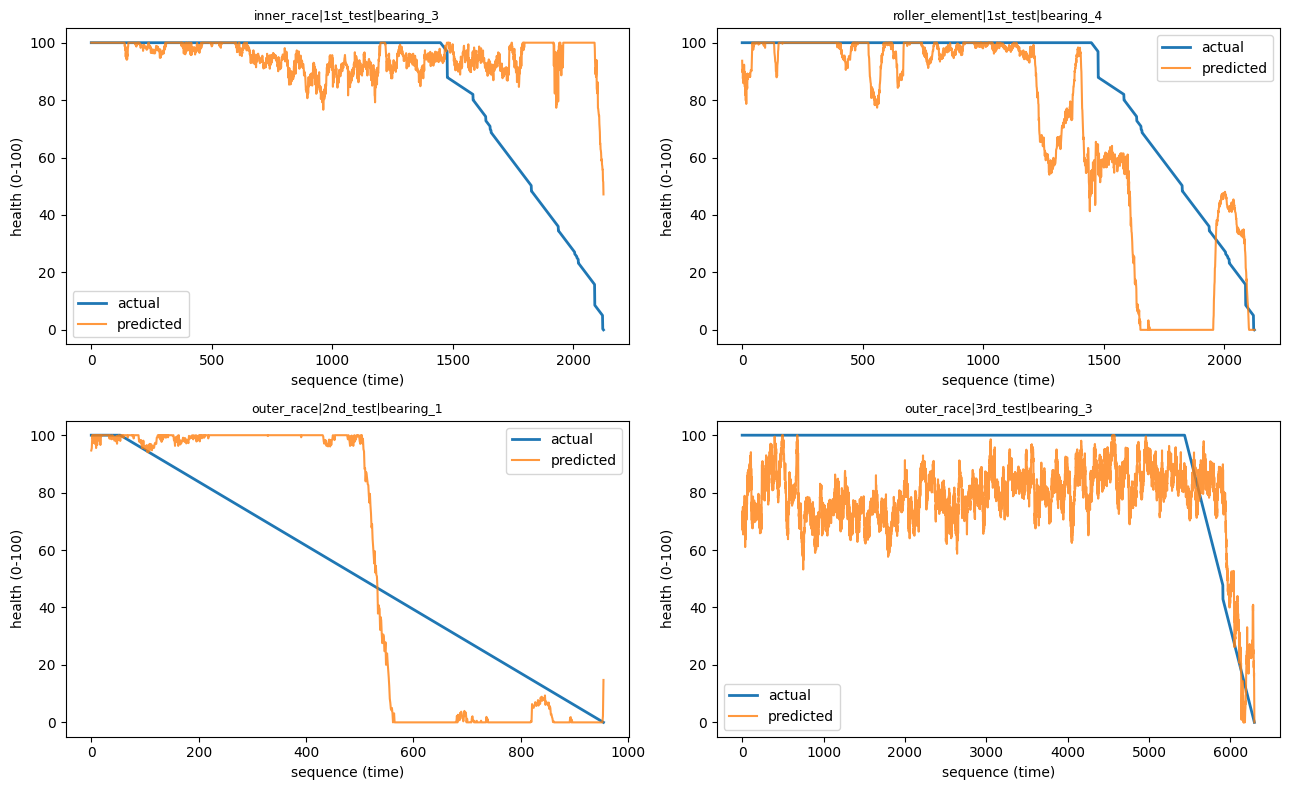

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, (yt, yp)) in zip(axes.ravel(), preds.items()):
    ax.plot(yt, label="actual", lw=2); ax.plot(yp, label="predicted", alpha=.8)
    ax.set_title(name, fontsize=9); ax.set_xlabel("sequence (time)"); ax.set_ylabel("health (0-100)"); ax.legend()
plt.tight_layout(); plt.show()

## Text comparison (copy this output back to the chat)

In [8]:
N_ROWS = 15
for name, (y_true, y_pred) in preds.items():
    life = runs[name]["life"]
    idx = np.linspace(0, len(y_true) - 1, N_ROWS).astype(int)
    err = y_pred - y_true
    print(f"\n=== {name} | life={life:.0f} h | n={len(y_true)} | cap={CAP_HOURS:.0f} h ===")
    print(f"{'step':>6} {'actual':>8} {'pred':>8} {'err':>8}")
    for i in idx:
        print(f"{i:6d} {y_true[i]:8.1f} {y_pred[i]:8.1f} {err[i]:8.1f}")
    print(f"MAE={np.mean(np.abs(err)):.1f} | RMSE={np.sqrt(np.mean(err**2)):.1f} | "
          f"bias={np.mean(err):.1f} | corr={np.corrcoef(y_true, y_pred)[0,1]:.3f}")
    for lo, hi, lbl in [(66.7, 100.1, "high health"), (33.3, 66.7, "mid"), (0, 33.3, "low (near failure)")]:
        m = (y_true >= lo) & (y_true < hi)
        if m.any():
            print(f"  {lbl:18s}: MAE={np.mean(np.abs(err[m])):.1f}, n={m.sum()}")

print("\n=== SUMMARY ===")
print(pd.DataFrame(results).round(2).to_string(index=False))


=== inner_race|1st_test|bearing_3 | life=828 h | n=2127 | cap=150 h ===
  step   actual     pred      err
     0    100.0    100.0      0.0
   151    100.0     95.4     -4.6
   303    100.0     98.8     -1.2
   455    100.0     99.0     -1.0
   607    100.0     98.9     -1.1
   759    100.0     95.9     -4.1
   911    100.0     87.9    -12.1
  1063    100.0     90.9     -9.1
  1214    100.0    100.0      0.0
  1366    100.0     84.8    -15.2
  1518     85.7     92.5      6.8
  1670     67.6     91.7     24.1
  1822     50.7    100.0     49.3
  1974     30.7    100.0     69.3
  2126      0.0     47.2     47.2
MAE=16.5 | RMSE=28.1 | bias=9.9 | corr=0.062
  high health       : MAE=5.9, n=1679
  mid               : MAE=45.4, n=272
  low (near failure): MAE=73.4, n=176

=== roller_element|1st_test|bearing_4 | life=828 h | n=2127 | cap=150 h ===
  step   actual     pred      err
     0    100.0     93.7     -6.3
   151    100.0     99.5     -0.5
   303    100.0    100.0      0.0
   455    1